# HDBSCAN: Clusters of Varying Density

**Family:** Unsupervised learning | **Level:** Advanced | **Dataset:** `digits` | **Runs on:** CPU, about 1 minute(s)

Build a hierarchy of density clusters and keep the stable ones.

## Table of Contents

1. [Learning Objectives](#1.-Learning-Objectives)
2. [Real-World Problem](#2.-Real-World-Problem)
3. [Research Paper](#3.-Research-Paper)
4. [Mathematical Foundation](#4.-Mathematical-Foundation)
5. [Dataset Introduction](#5.-Dataset-Introduction)
6. [Exploratory Data Analysis](#6.-Exploratory-Data-Analysis)
7. [Data Preprocessing](#7.-Data-Preprocessing)
8. [Algorithm Implementation](#8.-Algorithm-Implementation)
9. [Model Training](#9.-Model-Training)
10. [Evaluation](#10.-Evaluation)
11. [Visualization](#11.-Visualization)
12. [Interpretation](#12.-Interpretation)
13. [Experiments and Challenges](#13.-Experiments-and-Challenges)
14. [Research Discussion](#14.-Research-Discussion)
15. [Summary and Further Reading](#15.-Summary-and-Further-Reading)

## 1. Learning Objectives

**After this notebook you will understand:**

- Mutual reachability distance
- How stability selects clusters
- Why min_cluster_size replaces eps
- How soft probabilities describe membership

**Prerequisites:**

- Distances and vectors
- Standardising features

**Skills you will have afterwards:**

- Pick settings without labels
- Check stability
- Compare with a reference labelling

## 2. Real-World Problem

**Context.** Clusters in real data rarely share one density, so a single eps fails.

**The problem.** Cluster digit images in PCA space without choosing an eps.

**Why it matters.** Fewer tuning decisions and a per-row confidence.

**Why machine learning.** Density structure is not visible in raw pixels.

**Why this algorithm.** HDBSCAN extends DBSCAN across all density levels.

## 3. Research Paper

Entries are grouped by type. Bibliographic details marked *verified* were checked against the publisher record (Crossref) or the arXiv abstract page on 2026-11-17. Entries marked *not verified* come from the author's knowledge and must be checked before citing.

### Density-Based Clustering Based on Hierarchical Density Estimates

- **Type:** foundational paper
- **Authors:** Campello, R. J. G. B., Moulavi, D. and Sander, J.
- **Year and venue:** 2013, PAKDD 2013, LNCS 7819, pp. 160-172
- **DOI or URL:** https://doi.org/10.1007/978-3-642-37456-2_14
- **Verification:** Crossref 2026-11-17
- **Research objective:** Remove the single density threshold of DBSCAN.
- **Methodology:** Build a hierarchy over mutual reachability distance and extract stable clusters.
- **Dataset:** Synthetic and real datasets in the paper.
- **Main findings:** Finds clusters of varying density with one main parameter.
- **Limitations:** Still sensitive to the minimum cluster size.

### DBSCAN Revisited, Revisited: Why and How You Should (Still) Use DBSCAN

- **Type:** modern paper
- **Authors:** Schubert, E., Sander, J., Ester, M., Kriegel, H. P. and Xu, X.
- **Year and venue:** 2017, ACM Transactions on Database Systems 42(3):19
- **DOI or URL:** https://doi.org/10.1145/3068335
- **Verification:** Crossref 2026-11-17
- **Research objective:** Re-examine DBSCAN, its limits and its parameter choice.
- **Methodology:** Theory and discussion with examples.
- **Dataset:** Illustrative datasets.
- **Main findings:** Gives guidance on choosing epsilon and minPts and on when DBSCAN fails.
- **Limitations:** A single epsilon cannot fit clusters of very different density.

**Relationship to this notebook.** Campello et al. introduce HDBSCAN. We use the scikit-learn implementation, which may differ in details from the original code. This notebook does not reproduce the experimental protocol of any listed paper. It uses a different dataset and split, so numbers are not comparable with the paper.

## 4. Mathematical Foundation

**Core distance.** $d_{core}(x)$ is the distance to the minPts-th nearest neighbour.

**Mutual reachability.** $d_{mreach}(a,b) = \max\{d_{core}(a), d_{core}(b), d(a,b)\}$.

**Hierarchy.** Build the minimum spanning tree of the mutual reachability graph and remove edges from the largest to the smallest, giving a tree of clusters over density levels.

**Stability.** A cluster's stability is $\sum_{x \in C} (\lambda_{x} - \lambda_{birth})$ with $\lambda = 1/\text{distance}$. Clusters with higher stability than the sum of their children are kept.

**Limits.** Parameters min_cluster_size and min_samples still matter.

## 5. Dataset Introduction

**Optical Recognition of Handwritten Digits**, UCI, licence CC BY 4.0, DOI 10.24432/C50P49. scikit-learn ships 1797 images (the test part of the UCI data) as 8 by 8 grids, so 64 integer pixel features from 0 to 16. Target `digit`, ten classes. Limit: far smaller than MNIST.

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

from ml_lab.data import load_dataset
from ml_lab.evaluation import internal_scores, external_scores
from ml_lab.experiments import ExperimentRecord, save_figure
from ml_lab.utils import set_seed, print_environment
from ml_lab import visualization as viz

NOTEBOOK_ID = "hdbscan"
SEED = 42
set_seed(SEED)
viz.apply_style()
print_environment()

bundle = load_dataset("digits")
X_raw = bundle.X
y_true = bundle.y          # evaluation only
print("shape:", X_raw.shape)
display(pd.Series(bundle.describe_source(), name="source").to_frame())

python 3.13.18 | Linux-6.18.44-fc-v595-x86_64-with-glibc2.39
  numpy==2.5.3
  pandas==3.0.5
  scipy==1.18.1
  scikit-learn==1.9.1
  matplotlib==3.11.2
  xgboost==3.4.1
  lightgbm==4.7.0
  catboost==1.2.10
  umap-learn==0.6.0
  torch==2.15.0
  gymnasium==1.4.0
shape: (1797, 64)


,source
title,Optical Recognition of Handwritten Digits
source,UCI Machine Learning Repository
url,https://archive.ics.uci.edu/dataset/80/optical...
license,CC BY 4.0
doi,10.24432/C50P49
rows,1797
features,64
limits,"8x8 images, much smaller than MNIST."


## 6. Exploratory Data Analysis

We check size, missing values, label balance and feature relations. The reference labels are used for evaluation only, never for fitting. 

Rows and columns: (1797, 64)
Missing values: 0


,count,mean,std,min,25%,50%,75%,max
pixel_0_0,1797.0,0.000,0.000,0.0,0.0,0.0,0.0,0.0
pixel_0_1,1797.0,0.304,0.907,0.0,0.0,0.0,0.0,8.0
pixel_0_2,1797.0,5.205,4.755,0.0,1.0,4.0,9.0,16.0
pixel_0_3,1797.0,11.836,4.249,0.0,10.0,13.0,15.0,16.0
pixel_0_4,1797.0,11.848,4.287,0.0,10.0,13.0,15.0,16.0
pixel_0_5,1797.0,5.782,5.666,0.0,0.0,4.0,11.0,16.0
pixel_0_6,1797.0,1.362,3.326,0.0,0.0,0.0,0.0,16.0
pixel_0_7,1797.0,0.130,1.037,0.0,0.0,0.0,0.0,15.0
pixel_1_0,1797.0,0.006,0.094,0.0,0.0,0.0,0.0,2.0
pixel_1_1,1797.0,1.994,3.196,0.0,0.0,0.0,3.0,16.0


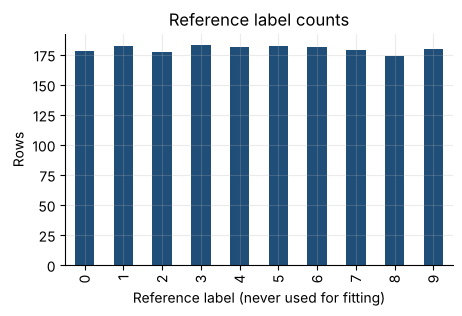

Mean absolute correlation between features: nan


In [2]:
print("Rows and columns:", X_raw.shape)
print("Missing values:", int(X_raw.isna().sum().sum()))
display(X_raw.describe().T.head(15).round(3))
fig, ax = plt.subplots(figsize=(5, 3))
pd.Series(y_true).value_counts().sort_index().plot.bar(ax=ax)
ax.set_xlabel("Reference label (never used for fitting)"); ax.set_ylabel("Rows"); ax.set_title("Reference label counts")
plt.show()
corr = X_raw.corr().abs().to_numpy(copy=True)
np.fill_diagonal(corr, 0)
print("Mean absolute correlation between features:", round(float(corr.mean()), 3))

## 7. Data Preprocessing

Same 10 component PCA projection as the DBSCAN notebook.

In [3]:
X = PCA(10, random_state=SEED).fit_transform(X_raw.values)
print(X.shape)

(1797, 10)


## 8. Algorithm Implementation

### 8.1 Concept

DBSCAN with every possible eps at once, then keep clusters that stay stable over a wide range of densities.

### 8.2 Python implementation from scratch

We compute core distances, the mutual reachability matrix and a single linkage tree on it, then cut at one level. This shows the first half of the algorithm. The stability based cluster selection is not implemented here.

In [4]:
from scipy.cluster.hierarchy import linkage, fcluster
from scipy.spatial.distance import squareform
sub = X[:400]
dist = np.sqrt(((sub[:, None] - sub[None]) ** 2).sum(axis=2))
core = np.sort(dist, axis=1)[:, 10]
mreach = np.maximum(np.maximum(core[:, None], core[None]), dist)
np.fill_diagonal(mreach, 0)
Z = linkage(squareform(mreach, checks=False), method="single")
cut = np.percentile(Z[:, 2], 90)
lab = fcluster(Z, cut, "distance")
sizes = np.bincount(lab)[1:]
print("clusters at one cut:", len(sizes), "| sizes >= 10:", int((sizes >= 10).sum()))
print("mean core distance:", round(float(core.mean()), 2), "| mean pairwise distance:", round(float(dist.mean()), 2))

clusters at one cut: 41 | sizes >= 10: 3
mean core distance: 18.1 | mean pairwise distance: 41.53


### 8.3 Library implementation

scikit-learn and scipy provide tested implementations.

### 8.4 Important parameters

| Parameter | Meaning |
|---|---|
| `min_cluster_size` | Smallest group accepted as a cluster. |
| `min_samples` | Neighbours for the core distance. |
| `cluster_selection_method` | `eom` or `leaf`. |

## 9. Model Training

We vary min_cluster_size and pick the setting with the best silhouette on non noise rows among settings with at most 40 percent noise.

In [5]:
from sklearn.cluster import HDBSCAN
rows = []
for mcs in [10, 15, 20, 30, 50]:
    lab = HDBSCAN(min_cluster_size=mcs).fit_predict(X)
    s = internal_scores(X, lab)
    rows.append({"min_cluster_size": mcs, "clusters": s["clusters"], "noise": s["noise_fraction"], "silhouette": s.get("Silhouette", np.nan)})
sweep = pd.DataFrame(rows)
display(sweep.round(3))
ok = sweep[(sweep.noise <= 0.40) & sweep.silhouette.notna()]
BEST = int(ok.loc[ok.silhouette.idxmax(), "min_cluster_size"]) if len(ok) else 15
model = HDBSCAN(min_cluster_size=BEST).fit(X)
labels = model.labels_
print("chosen min_cluster_size:", BEST)

,min_cluster_size,clusters,noise,silhouette
0,10,14,0.464,0.388
1,15,7,0.444,0.320
2,20,6,0.456,0.321
3,30,7,0.570,0.419
4,50,6,0.679,0.494


chosen min_cluster_size: 15


## 10. Evaluation

Internal scores need no labels: silhouette (higher is better, range -1 to 1), Davies-Bouldin (lower is better) and Calinski-Harabasz (higher is better). External scores (ARI and NMI) compare with a reference label that was never used for fitting. A reference label is not the truth about the data. It is one possible grouping.

In [6]:
METRICS = {**internal_scores(X, labels)}
mask = labels != -1
if mask.sum() > 1 and len(np.unique(labels[mask])) > 1:
    METRICS.update({k + "_nonnoise": v for k, v in external_scores(y_true[mask], labels[mask]).items()})
CONFIG = {"min_cluster_size": BEST, "pca_components": 10}
EXTRA = {"sweep": sweep.round(4).to_dict("records"), "mean_probability": float(model.probabilities_[mask].mean()) if mask.any() else None}

record = ExperimentRecord(notebook=NOTEBOOK_ID, family="unsupervised", algorithm="HDBSCAN", dataset="digits",
                          task="clustering", seed=SEED, config=CONFIG, metrics=METRICS, extra=EXTRA)
print("saved:", record.save())
display(pd.Series(METRICS, name="metric").round(4).to_frame())

saved: experiments/results/hdbscan.json


,metric
clusters,7.0000
noise_fraction,0.4441
Silhouette,0.3195
Davies_Bouldin,1.2930
Calinski_Harabasz,225.1519
ARI_nonnoise,0.6532
NMI_nonnoise,0.8520


## 11. Visualization

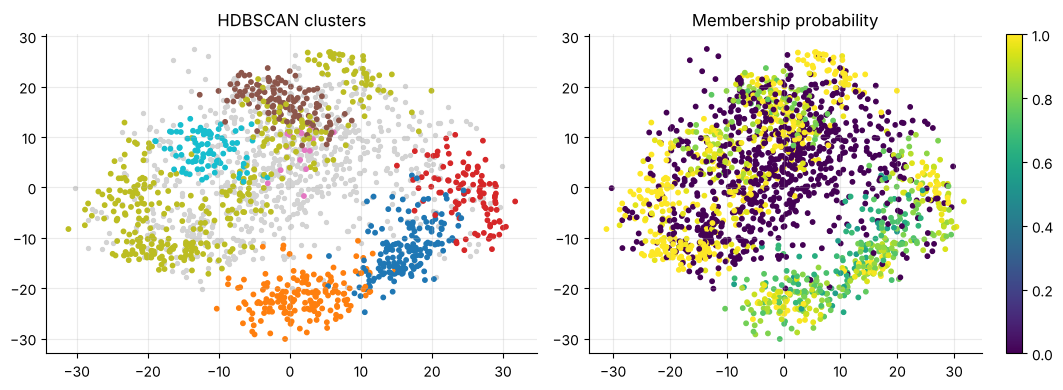

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
Z2 = PCA(2, random_state=SEED).fit_transform(X)
axes[0].scatter(Z2[labels == -1, 0], Z2[labels == -1, 1], c="lightgray", s=8)
axes[0].scatter(Z2[mask, 0], Z2[mask, 1], c=labels[mask], cmap="tab10", s=10); axes[0].set_title("HDBSCAN clusters")
sc = axes[1].scatter(Z2[:, 0], Z2[:, 1], c=model.probabilities_, cmap="viridis", s=10); axes[1].set_title("Membership probability")
plt.colorbar(sc, ax=axes[1]); plt.tight_layout(); save_figure(fig, NOTEBOOK_ID, "overview"); plt.show()

## 12. Interpretation

Low probability rows sit at the edge of a cluster. They are the ones to review first.

In [8]:
display(pd.crosstab(pd.Series(labels, name="cluster"), pd.Series(y_true, name="reference digit")))
print("rows with probability below 0.5:", int((model.probabilities_ < 0.5).sum()))

reference digit,0,1,2,3,4,5,6,7,8,9
cluster,,,,,,,,,,
-1,9,117,86,101,80,92,14,65,131,103
0,0,0,0,0,0,0,167,0,0,0
1,169,0,0,0,0,0,0,0,0,0
2,0,0,0,0,101,0,0,0,0,0
3,0,0,0,0,0,0,0,114,0,0
4,0,15,0,0,0,0,0,0,0,0
5,0,50,1,82,0,90,0,0,43,77
6,0,0,90,0,0,0,0,0,0,0


rows with probability below 0.5: 798


## 13. Experiments and Challenges

### Experiment 1: HDBSCAN versus DBSCAN

Compare noise and cluster count with the DBSCAN from the previous notebook.

In [9]:
from sklearn.cluster import DBSCAN
for name, lab in [("HDBSCAN", labels), ("DBSCAN eps=16", DBSCAN(eps=16, min_samples=10).fit_predict(X))]:
    s = internal_scores(X, lab)
    print(f"{name}: clusters {s['clusters']}, noise {s['noise_fraction']:.2f}")

HDBSCAN: clusters 7, noise 0.44
DBSCAN eps=16: clusters 2, noise 0.03


### Experiment 2: min_samples effect

Vary min_samples with min_cluster_size fixed.

In [10]:
for ms in [3, 5, 10, 20]:
    s = internal_scores(X, HDBSCAN(min_cluster_size=BEST, min_samples=ms).fit_predict(X))
    print(f"min_samples={ms}: clusters {s['clusters']}, noise {s['noise_fraction']:.2f}")

min_samples=3: clusters 14, noise 0.25
min_samples=5: clusters 12, noise 0.30


min_samples=10: clusters 11, noise 0.45


min_samples=20: clusters 7, noise 0.45


### Experiment 3: Selection method

Excess of mass (`eom`) versus leaf clusters.

In [11]:
for method in ["eom", "leaf"]:
    s = internal_scores(X, HDBSCAN(min_cluster_size=BEST, cluster_selection_method=method).fit_predict(X))
    print(f"{method}: clusters {s['clusters']}, noise {s['noise_fraction']:.2f}")

eom: clusters 7, noise 0.44


leaf: clusters 11, noise 0.53


### Exercises for learners

1. Repeat with `SEED = 7` and report which numbers move.
2. Change the number of rows by sampling 50 percent and compare the result.
3. Add pure noise columns and watch the internal scores.

## 14. Research Discussion

Campello et al. motivate HDBSCAN by the weakness of a global eps. Our comparison with DBSCAN checks whether the hierarchy gives a different cluster count and noise level on this data.

**Dataset and method differences.** The papers above use other data and protocols. We do not claim that our numbers agree or disagree with them. This notebook only shows whether the behaviour they describe appears on our data.

**Possible improvements.** Use cluster persistence plots and test on data with known varying density.

**Research limitations.** One dataset and one seed for the headline numbers. 

## 15. Summary and Further Reading

**Key takeaways**

- No eps, but still two parameters.
- Probabilities give per-row confidence.
- Noise remains possible.

**Use cases.** Exploratory clustering, embeddings, mixed density data.

**Limitations.** Parameters still matter.

**Recommended next notebook.** Gaussian mixture models.

**Further reading.** See `references.md` in this folder.